# K14 · Qualitative applications on OOD images (step 7, optional)

Official application scripts on a few Set A images, two at a time (one per T4):
- **Retargeting** to 1:2 (wide) and 2:1 (tall): does structure survive a change of shape?
- **Tileable generation** on the patterns, then tiled 2×2 to show the seams.
Uses the fused-attention presets (no N×N matrix). Qualitative only: a contact sheet is shown at the end.

**How to run (Kaggle):**
1. Right panel → *Session options*: **Accelerator = GPU T4 x2**, **Internet = On**.
2. Top right **Save Version** → *Save & Run All (Commit)* → Save. It runs in the background (you can close the tab);
   watch it under *View Active Events* / the version's **Logs** (progress lines every 2 min).
3. When it finishes, the result is the version's **Output**: `cs787_k14.zip`.
4. **Not finished?** (it stops itself before 2 hours) → *Add Input* → *Your Work* → this notebook's
   latest version → then *Save Version* again. It continues where it stopped.

In [1]:
import time
T_START = time.time()                      # session clock: work stops before SESSION_HOURS
NOTEBOOK = "K14_applications"
GITHUB_REPO   = "https://github.com/rishabh-vr/CS787-Single-Image-Diffusion-Editor.git"
GITHUB_BRANCH = "main"
SID_COMMIT    = "85381e3c6f29fc07144da854d86be07150404716"     # official code, audited commit
SINDDM_COMMIT = "e7107d9fd198928f26e278f99ec428e261726a45"  # SinDDM, audited commit
SESSION_HOURS = 1.9                        # hard stop: everything (incl. zipping) ends before 2 h

RETARGET = ["fp_house2", "fp_layout", "pat_p4", "pat_cmm", "ckt_24aa", "dia_life"]
TILEABLE = ["pat_p4", "pat_cmm", "pat_p2", "pat_demi1"]

In [2]:
import os, sys, subprocess, shutil, glob, json
if not os.path.isdir("/kaggle/working"):
    raise SystemExit("This notebook is written for Kaggle (kaggle.com/code).")
WORK, TMP = "/kaggle/working", "/tmp/cs787"
PROJECT = f"{TMP}/project"
shutil.rmtree(PROJECT, ignore_errors=True)
os.makedirs(TMP, exist_ok=True)
r = subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", GITHUB_BRANCH, GITHUB_REPO, PROJECT],
                   capture_output=True, text=True)
if r.returncode:
    raise SystemExit("Could not download the code from GitHub. Turn Internet ON: right panel -> Session options -> "
                     "Internet (needs a phone-verified Kaggle account), then run again.\n" + r.stderr)
sys.path.insert(0, f"{PROJECT}/src")
os.environ["PYTHONPATH"] = f"{PROJECT}/src" + os.pathsep + os.environ.get("PYTHONPATH", "")
from sidx.kaggle import gather_inputs, unpack_own, pack
from sidx.progress import Bars
print("code:", subprocess.run(["git", "-C", PROJECT, "log", "-1", "--format=%h %s"], capture_output=True, text=True).stdout)
gather_inputs()          # results of earlier versions attached under /kaggle/input (resume)

code: 992526f Results tables from the Kaggle runs (K10-K13); Table 1 uses raw pixel diversity; dedupe identical Set B inputs

[resume] nothing attached under /kaggle/input: starting from scratch


[]

In [3]:
import torch
N_GPUS = torch.cuda.device_count()
if N_GPUS == 0:
    raise SystemExit("No GPU. Right panel -> Session options -> Accelerator -> 'GPU T4 x2', then run again.")
cap = torch.cuda.get_device_capability(0)
if f"sm_{cap[0]}{cap[1]}" not in torch.cuda.get_arch_list():
    raise SystemExit(f"{torch.cuda.get_device_name(0)} is not supported by this PyTorch build: choose 'GPU T4 x2' (not P100).")
print(subprocess.run(["nvidia-smi", "--query-gpu=index,name,memory.total", "--format=csv"], capture_output=True, text=True).stdout)
print("torch", torch.__version__, "| CUDA", torch.version.cuda, "|", N_GPUS, "GPU(s) -> all of them are used")

index, name, memory.total [MiB]
0, Tesla T4, 15360 MiB
1, Tesla T4, 15360 MiB

torch 2.11.0+cu130 | CUDA 13.0 | 2 GPU(s) -> all of them are used


In [4]:
SID_ROOT = f"{TMP}/efficient-SID-code"
if not os.path.exists(SID_ROOT):
    subprocess.run(["git", "clone", "-q", "https://github.com/haojunqiu/efficient-SID-code", SID_ROOT], check=True)
subprocess.run(["git", "-C", SID_ROOT, "checkout", "-q", SID_COMMIT], check=True)
!pip install -q -r {PROJECT}/env/requirements-colab.txt
!pip install -q --no-deps -e {SID_ROOT}
!pip install -q --no-deps -e {PROJECT}
os.environ["SID_ROOT"] = SID_ROOT
sys.path.insert(0, SID_ROOT)
import efficient_sid, sidx
print("efficient_sid OK | sidx", sidx.__version__)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-tools 1.85.1 requires setuptools>=77.0.1, but you have setuptools 69.5.1 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for efficient-sid (pyproject.toml) ... done
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for sidx (pyproject.toml) ... done
efficient_sid OK | sidx 0.1.0


In [5]:
from PIL import Image
from sidx.gpupool import Task, run_pool
unpack_own()
OUT = f"{WORK}/outputs/qualitative"; os.makedirs(OUT, exist_ok=True)
IMG = lambda i: f"{PROJECT}/data/ood/setA/{i}.png"
FP32 = ["precision.dtype=float32", "image_denoiser.patch_denoiser.bottleneck_dtype=float32"]
tasks, targets = [], []
for i in RETARGET:
    W, H = Image.open(IMG(i)).size
    for tag, size in (("wide", f"({H},{2 * W})"), ("tall", f"({2 * H},{W})")):
        dst = f"{OUT}/retarget_{i}_{tag}.png"; targets.append(dst)
        if not os.path.exists(dst):
            tasks.append(Task(f"retarget_{i}_{tag}", [sys.executable, "scripts/sample_retarget.py", "--config",
                "configs/retarget/pixel_exact_flash_attn.yaml", f"image_path={IMG(i)}", f"output_size={size}",
                f"final_output_path={dst}", *FP32, "image_denoiser.patch_denoiser.query_chunks=4"], cwd=SID_ROOT))
for i in TILEABLE:
    dst = f"{OUT}/tileable_{i}.png"; targets.append(dst)
    if not os.path.exists(dst):
        tasks.append(Task(f"tileable_{i}", [sys.executable, "scripts/sample_tileable.py", "--config",
            "configs/tileable/pixel_exact_flash_attn.yaml", f"image_path={IMG(i)}", f"final_output_path={dst}", *FP32], cwd=SID_ROOT))
poll = lambda: {"qualitative": (sum(os.path.exists(t) for t in targets), len(targets))}
run_pool(tasks, poll, n_gpus=N_GPUS, log_dir=f"{WORK}/logs/{NOTEBOOK}", unit="image")
for i in TILEABLE:
    p = f"{OUT}/tileable_{i}.png"
    if os.path.exists(p):
        im = Image.open(p).convert("RGB"); t = Image.new("RGB", (2 * im.width, 2 * im.height))
        for a in range(2):
            for b in range(2):
                t.paste(im, (a * im.width, b * im.height))
        t.save(f"{OUT}/tileable_{i}_2x2.png")

[pool] 16 tasks on 2 slot(s), 2 GPU(s); logs in /kaggle/working/logs/K14_applications
[13:03:09] qualitative: 0/16 images (0%) | 0.0/min | ETA ?
[13:03:09] tasks 0/16 finished | running: GPU0: retarget_fp_house2_wide (0 min), GPU1: retarget_fp_house2_tall (0 min)
[13:05:09] qualitative: 0/16 images (0%) | 0.0/min | ETA ?
[13:05:09] tasks 0/16 finished | running: GPU0: retarget_fp_house2_wide (2 min), GPU1: retarget_fp_house2_tall (2 min)
[13:07:09] qualitative: 0/16 images (0%) | 0.0/min | ETA ?
[13:07:09] tasks 0/16 finished | running: GPU0: retarget_fp_house2_wide (4 min), GPU1: retarget_fp_house2_tall (4 min)
[13:09:09] qualitative: 2/16 images (12%) | 0.3/min | ETA 42m00s
[13:09:09] tasks 2/16 finished | running: GPU0: retarget_fp_layout_tall (1 min), GPU1: retarget_fp_layout_wide (1 min)
[13:11:09] qualitative: 2/16 images (12%) | 0.2/min | ETA 56m00s
[13:11:09] tasks 2/16 finished | running: GPU0: retarget_fp_layout_tall (3 min), GPU1: retarget_fp_layout_wide (3 min)
[13:13:09] q

retarget_ckt_24aa_tall.png


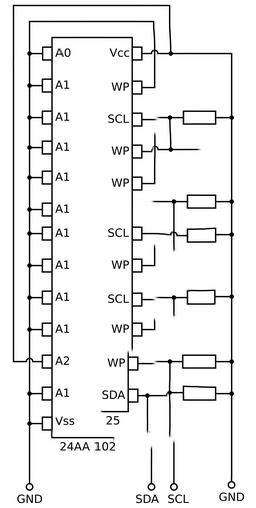

retarget_ckt_24aa_wide.png


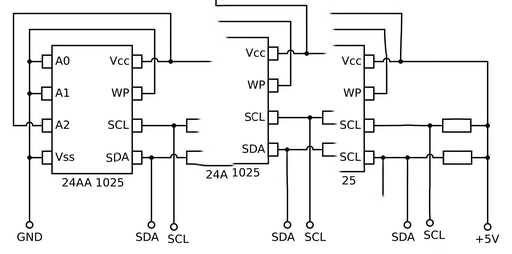

retarget_dia_life_tall.png


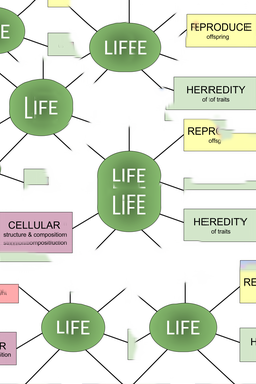

retarget_dia_life_wide.png


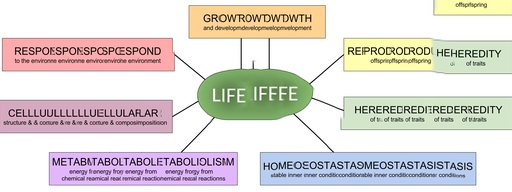

retarget_fp_house2_tall.png


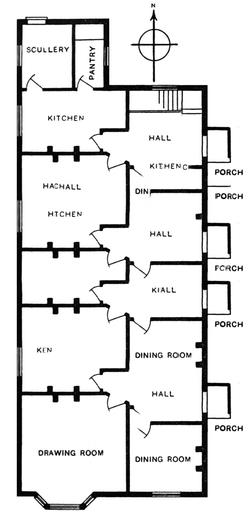

retarget_fp_house2_wide.png


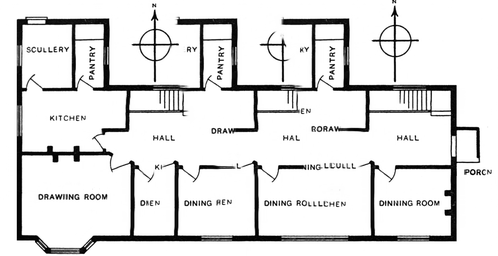

retarget_fp_layout_tall.png


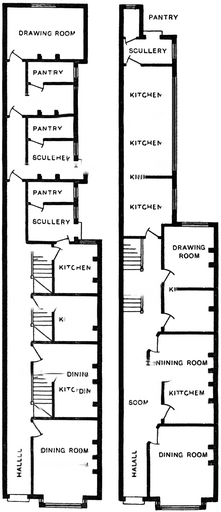

retarget_fp_layout_wide.png


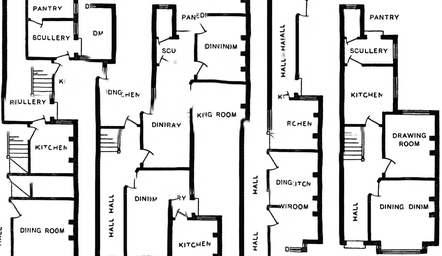

retarget_pat_cmm_tall.png


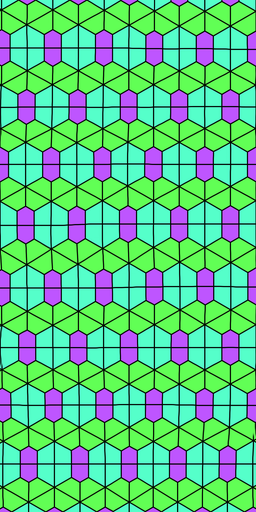

retarget_pat_cmm_wide.png


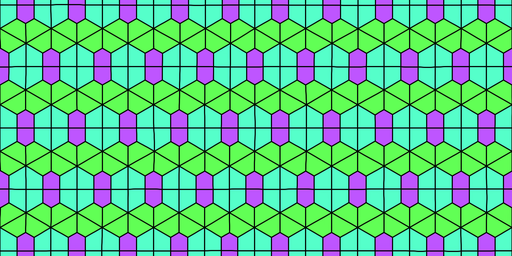

retarget_pat_p4_tall.png


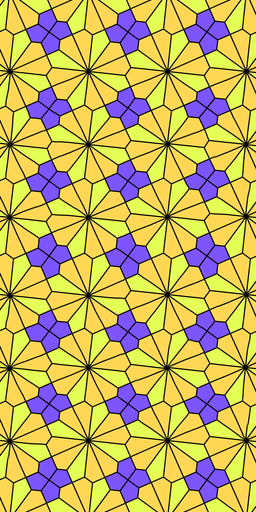

retarget_pat_p4_wide.png


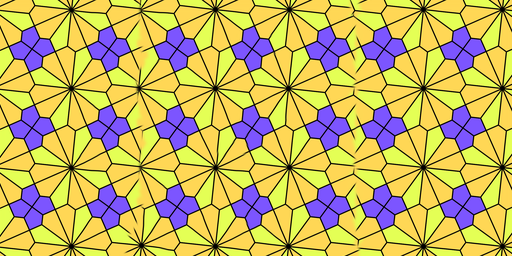

tileable_pat_cmm_2x2.png


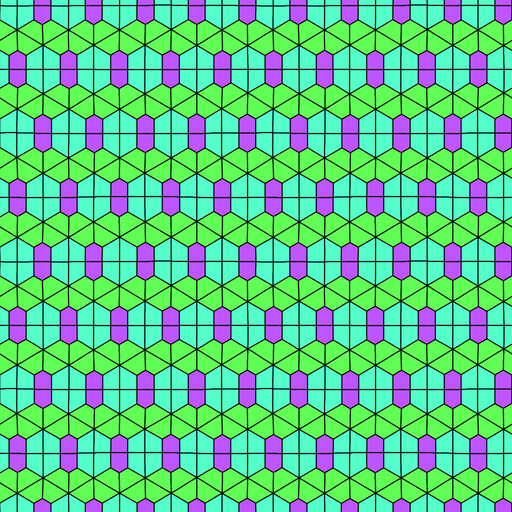

tileable_pat_cmm_input_tiled_2x2.png


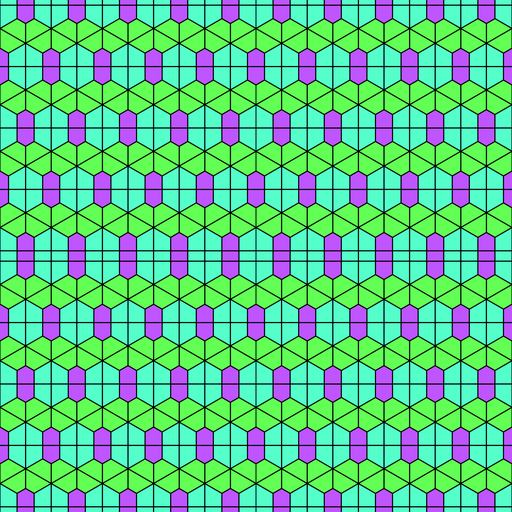

tileable_pat_cmm_sample_tiled_2x2.png


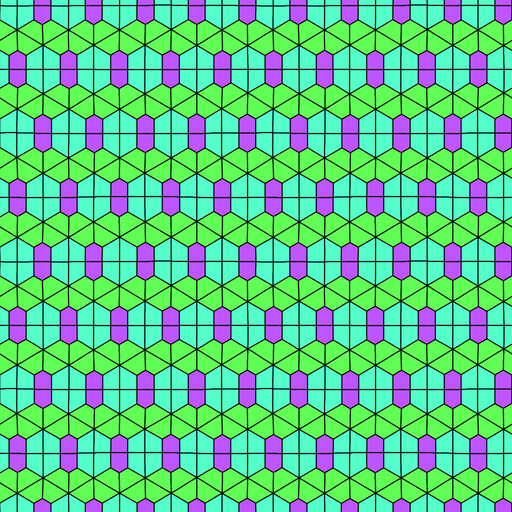

tileable_pat_demi1_2x2.png


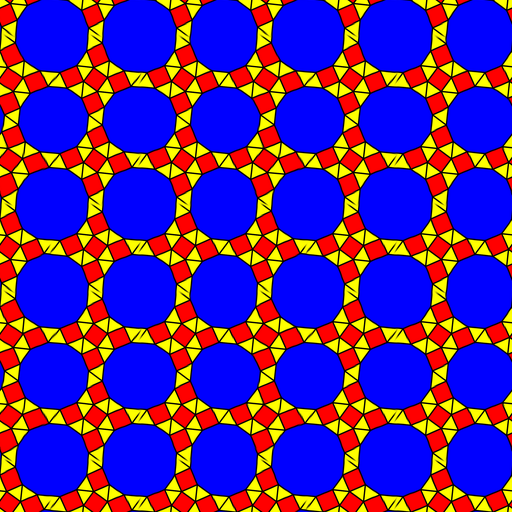

tileable_pat_demi1_input_tiled_2x2.png


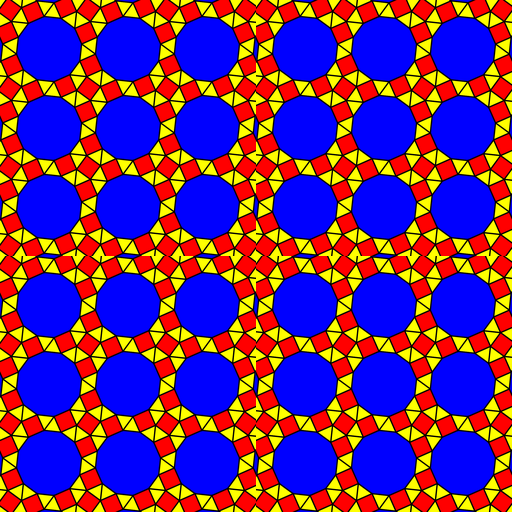

tileable_pat_demi1_sample_tiled_2x2.png


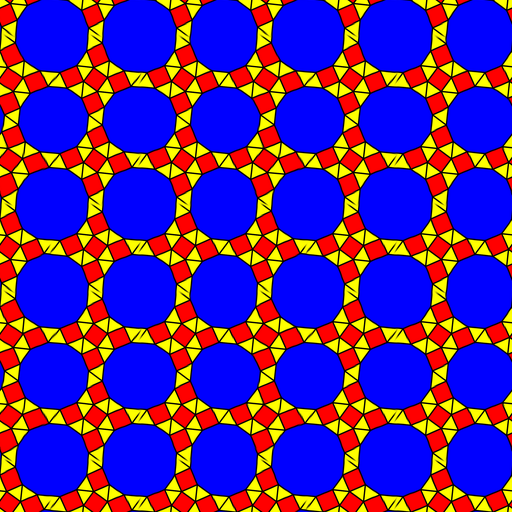

tileable_pat_p2_2x2.png


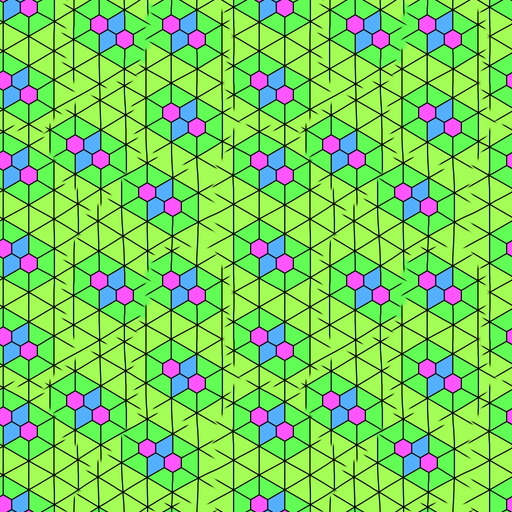

tileable_pat_p2_input_tiled_2x2.png


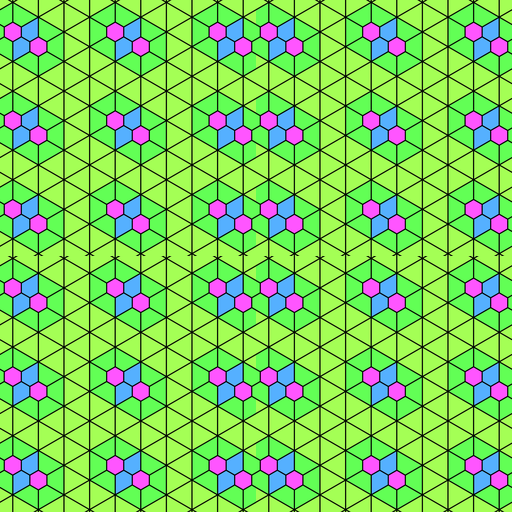

tileable_pat_p2_sample_tiled_2x2.png


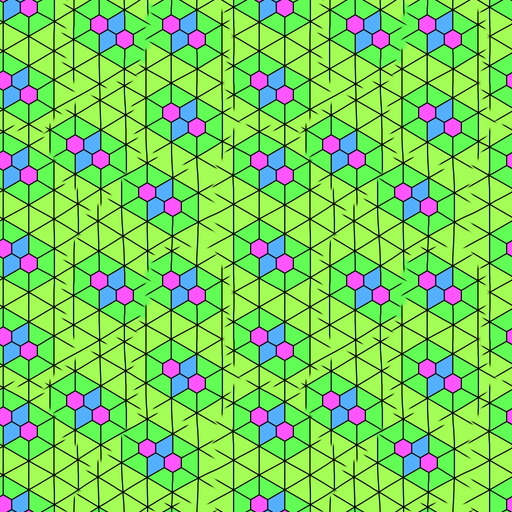

tileable_pat_p4_2x2.png


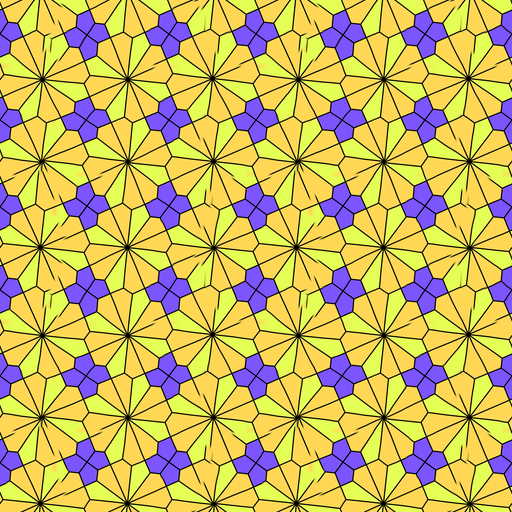

tileable_pat_p4_input_tiled_2x2.png


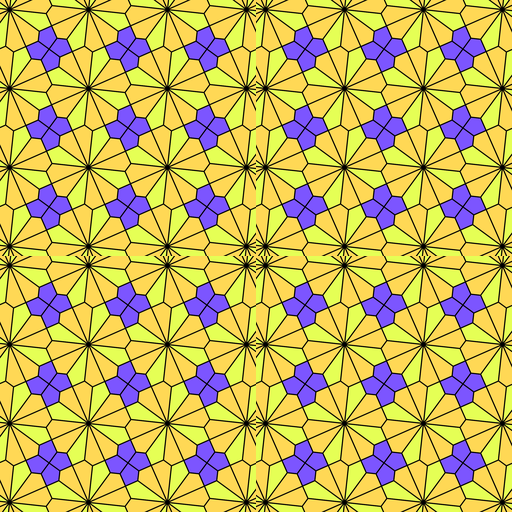

tileable_pat_p4_sample_tiled_2x2.png


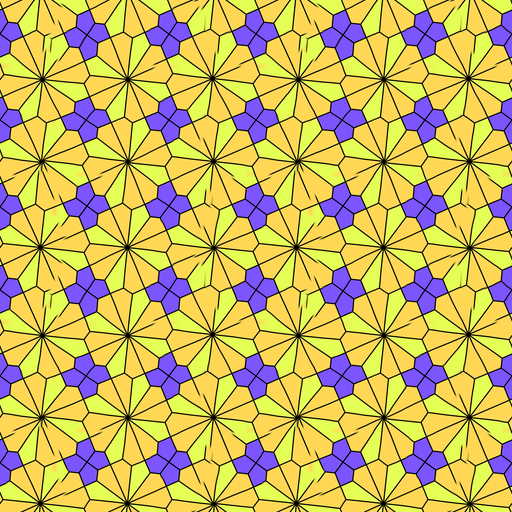

[pack] 40 files -> /kaggle/working/cs787_k14.zip (5.4 MB)


PosixPath('/kaggle/working/cs787_k14.zip')

In [6]:
from IPython.display import display
for f in sorted(glob.glob(f"{OUT}/retarget_*.png")) + sorted(glob.glob(f"{OUT}/tileable_*_2x2.png")):
    im = Image.open(f).convert("RGB"); w = min(600, im.width)
    print(os.path.basename(f)); display(im.resize((w, int(im.height * w / im.width))))
pack("k14", kinds=("outputs",))

In [7]:
os.makedirs(f"{WORK}/logs", exist_ok=True)
!pip freeze > {WORK}/logs/{NOTEBOOK}_pip_freeze.txt
print("finished; output files:", sorted(os.listdir(WORK)))

finished; output files: ['__notebook__.ipynb', 'cs787_k14.zip', 'logs']
